<center><h1>Zheng_Yifei_Midterm</h1></center>
<br>
<br>

Name: Yifei Zheng
<br>
Github Username: yyl-ff
<br>
USC ID: 8538054131

## 8. Predicting Student Grades with Linear Regression

### (a) Data Exploration and Pre-processing

#### i. Import the Dataset

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data_path = "student+performance/student/student-mat.csv"
df = pd.read_csv(data_path, sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


#### ii. Select and Pre-process the Variables

In [18]:
from IPython.display import display

selected_columns = [
    "age", "studytime", "schoolsup", "goout",
    "Dalc", "Walc", "health", "absences", "G3"
]

data = df[selected_columns].copy()

data["schoolsup"] = data["schoolsup"].map({
    "no": 0,
    "yes": 1
})

data["alc"] = (data["Dalc"] + data["Walc"]) / 2
data = data.drop(columns=["Dalc", "Walc"])

print("First five rows of the pre-processed dataset:")
display(data.head())

print("\nDataset information:")
data.info()

print("\nDescriptive statistics:")
display(data.describe())

print("\nMissing values:")
print(data.isnull().sum())

First five rows of the pre-processed dataset:


,age,studytime,schoolsup,goout,health,absences,G3,alc
0,18,2,1,4,3,6,6,1.0
1,17,2,0,3,3,4,6,1.0
2,15,2,1,2,3,10,10,2.5
3,15,3,0,2,5,2,15,1.0
4,16,2,0,2,5,4,10,1.5



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        395 non-null    int64  
 1   studytime  395 non-null    int64  
 2   schoolsup  395 non-null    int64  
 3   goout      395 non-null    int64  
 4   health     395 non-null    int64  
 5   absences   395 non-null    int64  
 6   G3         395 non-null    int64  
 7   alc        395 non-null    float64
dtypes: float64(1), int64(7)
memory usage: 24.8 KB

Descriptive statistics:


,age,studytime,schoolsup,goout,health,absences,G3,alc
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.035443,0.129114,3.108861,3.554430,5.708861,10.415190,1.886076
std,1.276043,0.839240,0.335751,1.113278,1.390303,8.003096,4.581443,0.992195
min,15.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000
25%,16.000000,1.000000,0.000000,2.000000,3.000000,0.000000,8.000000,1.000000
50%,17.000000,2.000000,0.000000,3.000000,4.000000,4.000000,11.000000,1.500000
75%,18.000000,2.000000,0.000000,4.000000,5.000000,8.000000,14.000000,2.500000
max,22.000000,4.000000,1.000000,5.000000,5.000000,75.000000,20.000000,5.000000



Missing values:
age          0
studytime    0
schoolsup    0
goout        0
health       0
absences     0
G3           0
alc          0
dtype: int64


#### iii. Detect Outliers Using the IQR Method

,Feature,Number of Outliers
0,age,1
1,studytime,27
2,schoolsup,51
3,goout,0
4,health,0
5,absences,15
6,alc,9


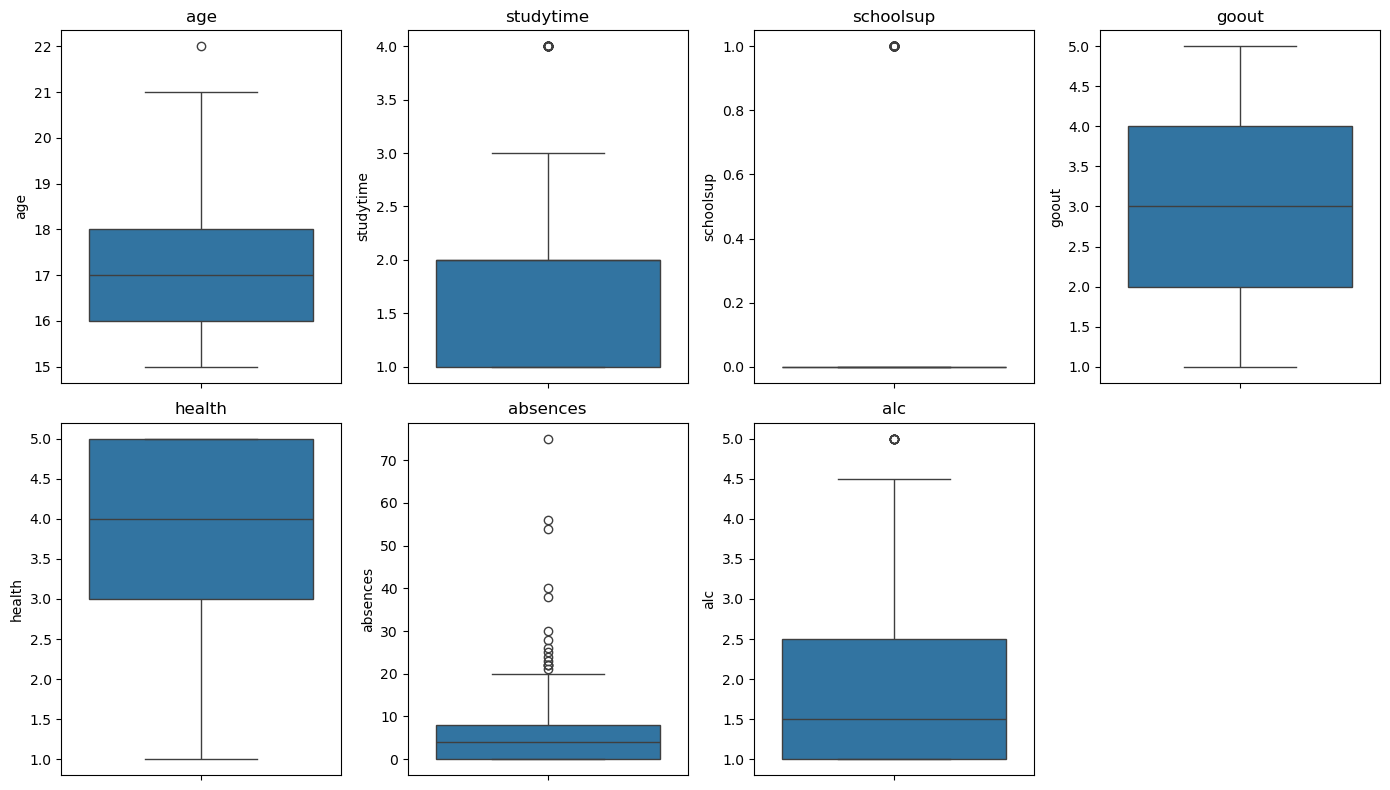

In [23]:
X = data.drop(columns=["G3"])

outlier_counts = {}

for column in X.columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X[
        (X[column] < lower_bound) |
        (X[column] > upper_bound)
    ]

    outlier_counts[column] = len(outliers)

outlier_table = pd.DataFrame({
    "Feature": outlier_counts.keys(),
    "Number of Outliers": outlier_counts.values()
})

display(outlier_table)

plt.figure(figsize=(14, 8))

for index, column in enumerate(X.columns, start=1):
    plt.subplot(2, 4, index)
    sns.boxplot(y=X[column])
    plt.title(column)

plt.tight_layout()
plt.show()

#### iv. Standardization and Principal Component Analysis

First five rows of the standardized data:


,age,studytime,schoolsup,goout,health,absences,alc
0,1.023046,-0.042286,2.597133,0.801479,-0.399289,0.036424,-0.894179
1,0.238380,-0.042286,-0.385040,-0.097908,-0.399289,-0.213796,-0.894179
2,-1.330954,-0.042286,2.597133,-0.997295,-0.399289,0.536865,0.619538
3,-1.330954,1.150779,-0.385040,-0.997295,1.041070,-0.464016,-0.894179
4,-0.546287,-0.042286,-0.385040,-0.997295,1.041070,-0.213796,-0.389607


Explained variance ratio:
PC1: 0.2368
PC2: 0.1714
Total: 0.4081


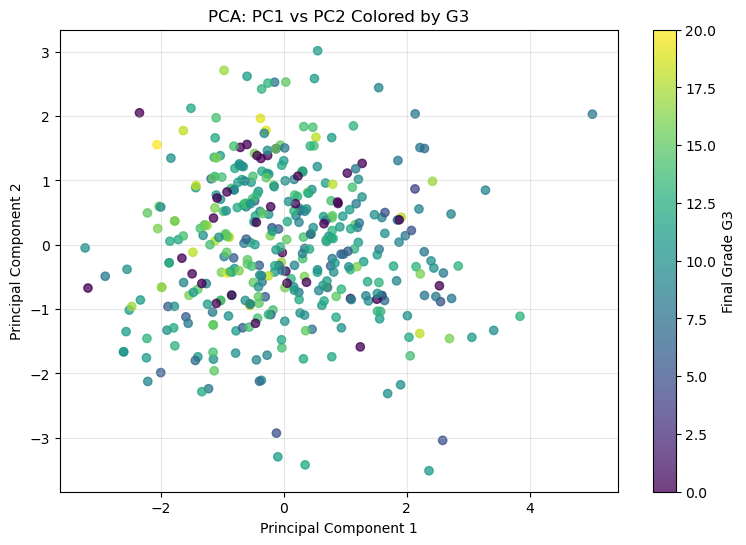

PCA component loadings:


,PC1,PC2
age,0.381940,0.589260
studytime,-0.329734,0.385671
schoolsup,-0.248184,-0.464202
goout,0.493755,-0.139613
health,0.080545,-0.400925
absences,0.280106,0.182798
alc,0.595871,-0.273677


Feature contributing the most to PC1: alc
Feature contributing the most to PC2: age


In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = data.drop(columns=["G3"])
y = data["G3"]

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=X.columns,
    index=X.index
)

print("First five rows of the standardized data:")
display(X_scaled.head())

## Create a scatterplot of PC1 vs PC2
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

pca_data = pd.DataFrame(
    principal_components,
    columns=["PC1", "PC2"],
    index=X.index
)

pca_data["G3"] = y

print("Explained variance ratio:")
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))
print("Total:", round(pca.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    pca_data["PC1"],
    pca_data["PC2"],
    c=pca_data["G3"],
    cmap="viridis",
    alpha=0.75
)

plt.colorbar(scatter, label="Final Grade G3")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: PC1 vs PC2 Colored by G3")
plt.grid(alpha=0.3)
plt.show()


# Create a table of PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=X.columns
)

print("PCA component loadings:")
display(loadings)

pc1_feature = loadings["PC1"].abs().idxmax()
pc2_feature = loadings["PC2"].abs().idxmax()

print("Feature contributing the most to PC1:", pc1_feature)
print("Feature contributing the most to PC2:", pc2_feature)

PC1 explains 23.68% of the differences in the data, and PC2 explains 17.14%. Together, they explain 40.81%.

Alcohol use (`alc`) has the biggest effect on PC1, while age has the biggest effect on PC2.

The colors overlap a lot in the plot. This means PC1 and PC2 cannot clearly separate students with different final grades.

### (b) Linear Regression

#### i. Split the Data into Training and Test Sets

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.20,
    random_state=552
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (316, 7)
X_test shape: (79, 7)
y_train shape: (316,)
y_test shape: (79,)


#### ii. Build the Linear Regression, Ridge, and Lasso Models

In [34]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

linear_model = LinearRegression()
ridge_model = Ridge(alpha=0.1)
lasso_model = Lasso(alpha=0.1)

linear_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

print("All three models were trained successfully.")

All three models were trained successfully.


#### iii. Evaluate the Three Models

Model evaluation results:


,Model,MAE,RMSE,R2
0,Linear Regression,3.4180,4.7558,0.0282
1,Ridge,3.4181,4.7559,0.0282
2,Lasso,3.4471,4.7938,0.0126


Best model based on MAE: Linear Regression
Best model based on RMSE: Linear Regression
Best model based on R2: Linear Regression


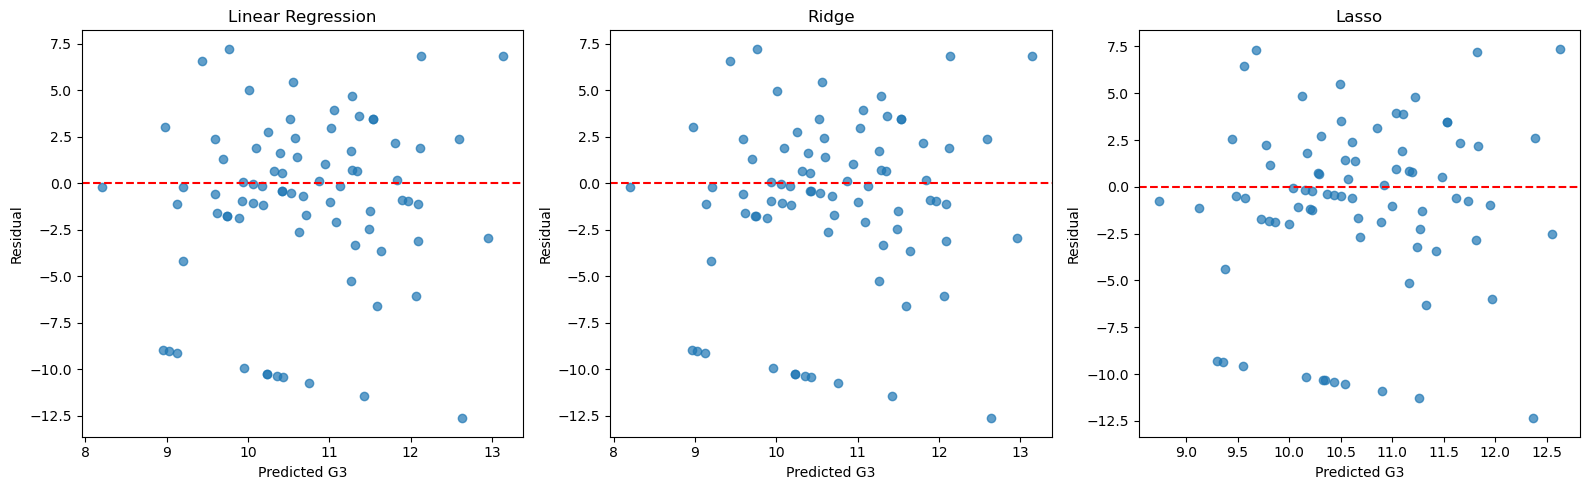

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_predictions = linear_model.predict(X_test)
ridge_predictions = ridge_model.predict(X_test)
lasso_predictions = lasso_model.predict(X_test)

predictions = {
    "Linear Regression": linear_predictions,
    "Ridge": ridge_predictions,
    "Lasso": lasso_predictions
}

results = []

for model_name, y_pred in predictions.items():
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

print("Model evaluation results:")
display(results_df.round(4))

best_mae_model = results_df.loc[
    results_df["MAE"].idxmin(), "Model"
]

best_rmse_model = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

best_r2_model = results_df.loc[
    results_df["R2"].idxmax(), "Model"
]

print("Best model based on MAE:", best_mae_model)
print("Best model based on RMSE:", best_rmse_model)
print("Best model based on R2:", best_r2_model)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test - y_pred

    ax.scatter(y_pred, residuals, alpha=0.7)
    ax.axhline(y=0, color="red", linestyle="--")
    ax.set_title(model_name)
    ax.set_xlabel("Predicted G3")
    ax.set_ylabel("Residual")

plt.tight_layout()
plt.show()

#### iv. Interpretation of R-squared Values

The Linear Regression and Ridge models both have an R-squared value of about 0.028. This means they explain only about 2.8% of the differences in students' final grades.

The Lasso model has an R-squared value of about 0.013, so it explains only about 1.3% of the differences in final grades.

All three R-squared values are close to zero. This means the selected features do not predict G3 very well. Linear Regression performs slightly better than Ridge and Lasso, but its performance is still weak.

#### v. Model Coefficients and Intercepts

In [45]:
parameter_names = ["Intercept"] + list(X_train.columns)

linear_values = [linear_model.intercept_] + list(linear_model.coef_)
ridge_values = [ridge_model.intercept_] + list(ridge_model.coef_)
lasso_values = [lasso_model.intercept_] + list(lasso_model.coef_)

coefficient_table = pd.DataFrame({
    "Parameter": parameter_names,
    "Linear Regression": linear_values,
    "Ridge": ridge_values,
    "Lasso": lasso_values
})

print("Coefficients and intercepts of the three models:")
display(coefficient_table.round(4))

Coefficients and intercepts of the three models:


,Parameter,Linear Regression,Ridge,Lasso
0,Intercept,10.6294,10.6294,10.6251
1,age,-0.7811,-0.7807,-0.6304
2,studytime,0.4448,0.4447,0.3491
3,schoolsup,-0.6825,-0.6822,-0.5475
4,goout,-0.5825,-0.5823,-0.4856
5,health,-0.2433,-0.2432,-0.1416
6,absences,0.1928,0.1927,0.0720
7,alc,0.0371,0.0369,-0.0000


#### vi. Relationship Between the Independent Variables and G3

Because the independent variables were standardized, the coefficient sizes can be compared directly.

- **age:** It has a negative relationship with G3. Older students tend to have slightly lower final grades.

- **studytime:** It has a positive relationship with G3. Students who spend more time studying tend to have higher final grades.

- **schoolsup:** It has a negative coefficient. Students who receive extra school support tend to have lower final grades. However, this does not mean that school support causes lower grades. Students who need support may already be having difficulty in school.

- **goout:** It has a negative relationship with G3. Going out more often is associated with slightly lower final grades.

- **health:** It has a small negative relationship with G3 in these models.

- **absences:** It has a small positive coefficient, which is unexpected. Since the coefficient is small and the models have very low R-squared values, this result may be caused by noise or other factors that are not included in the model.

- **alc:** It has almost no relationship with G3. Its coefficient is close to zero, and Lasso reduces it to zero.

Overall, age has the strongest negative coefficient, while study time has the strongest positive coefficient. However, all three models have very low R-squared values, so these relationships are weak and should be interpreted carefully. They show associations, not cause-and-effect relationships.

#### vii. Differences Between Regularization Methods

Ridge and Lasso both add a penalty to reduce the size of the model coefficients.

- **Ridge** makes the coefficients smaller, but it usually does not reduce them to exactly zero. In this result, Ridge is almost the same as Linear Regression because the regularization strength is small.

- **Lasso** can make some coefficients exactly zero, so it can also be used for feature selection. In this result, Lasso reduces the coefficient of `alc` to zero. This means that alc does not help much when predicting G3.

Linear Regression and Ridge have almost the same performance, while Lasso performs slightly worse. Therefore, regularization does not improve the model for this dataset.

The low R-squared values show that the selected features explain only a small part of the differences in final grades. Important information may be missing from the model. For example, previous grades, family background, motivation, and other school-related factors may help predict G3 better.

#### viii. Effect of Increasing the Regularization Strength

If alpha is increased, Ridge and Lasso will apply a stronger penalty to the model. As a result, the coefficients will become smaller. Lasso may also reduce more coefficients to zero and remove more features from the model.

Stronger regularization may help reduce overfitting. However, if alpha becomes too large, the model may become too simple and underfit the data. In that case, MAE and RMSE may increase, while R-squared may decrease.

Since the current models do not show strong overfitting, increasing alpha may not improve their test performance.

#### ix. Suggested Feature Engineering Methods

The following methods may help improve the model:

- Add useful features from the original dataset, such as previous grades G1 and G2, failures, family support, and parents' education.


- Create polynomial features to capture relationships that are not completely linear.

- Group some variables into categories. For example, absences can be divided into low, medium, and high groups.

- Check unusual values in variables such as absences and reduce their influence if necessary.

- Try different ways to combine Dalc and Walc instead of only using their average.

Previous grades, especially G1 and G2, would probably improve the prediction the most because they are directly related to a student's final grade.